# ST-GNN ChebConv Experiment

Spatiotemporal graph neural network for Congruent vs Incongruent Pure. Nodes are electrodes, edges come from scalp distance, node features are theta/alpha DE over temporal windows, ChebConv extracts spatial structure, and a temporal 1D CNN captures dynamics.


### Spatio-Temporal Graph Neural Network (ST-GNN) Pipeline

This model extracts spatial patterns via Chebyshev Graph Convolutions on an electrode connectivity graph (built from standard 10-05 scalp coordinate distances) and temporal dynamics via 1D Conv layers over time-window features.

```mermaid
graph TD
    A[Input Features: batch, windows, nodes, features] --> B[Chebyshev Graph Convolution: Spatial Filter]
    B --> C[Spatial Node Pooling: Average over nodes]
    C --> D[Temporal 1D CNN: Conv1d, BN, ELU, Dropout]
    D --> E[Temporal Pooling: Average over windows]
    E --> F[Fully Connected Classifier]
    F --> G[Classification Output]
```

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt

# %pip install -q mne
import mne
import numpy as np
import pandas as pd
import seaborn as sns
import torch

# Prefer either the Colab-mounted path or the local repo path
try:
    from google.colab import drive

    IN_COLAB = True
    drive.mount("/content/drive")
    SRC_DIR = Path("/content/drive/MyDrive/TFG_Nils_2026/03_Codi")
except Exception:
    IN_COLAB = False
    NOTEBOOK_DIR = Path.cwd()
    SRC_DIR = NOTEBOOK_DIR.parent.parent / "src"

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from br_analysis import BinaryTaskConfig, RawEpochSpec, detect_project_paths, load_raw_epoch_dataset, get_task_config
from br_analysis.torch_training import (
    TorchTrainConfig,
    cross_validate_torch_model,
    plot_fold_metrics,
    plot_torch_history,
)

warnings.filterwarnings("ignore", category=RuntimeWarning)
mne.set_log_level("WARNING")
RANDOM_SEED = 42
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if DEVICE == "cuda":
    torch.backends.cudnn.benchmark = True
    print(f"Using CUDA GPU: {torch.cuda.get_device_name(0)}")
else:
    print("CUDA is not available; using CPU.")

from br_analysis import electrode_distance_adjacency, temporal_band_features
from br_analysis.torch_models import STGNNChebConv

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
CUDA is not available; using CPU.


## Task And Output Paths


In [ ]:
TASK_TAG = "c_vs_ip_stgnn"
paths = detect_project_paths("c_vs_i_stgnn", in_colab=IN_COLAB)
SELECTED_SUBJECTS_CSV = paths.analysis_root / "exploration" / "tables" / "subjectes_seleccionats.csv"
MAX_SUBJECTS = 24

task = get_task_config("c_vs_ip", paths.analysis_root, name=TASK_TAG, analysis_window=(0.0, 1.5))

print(f"Projecte: {paths.project_dir}")
print(f"Dades: {paths.data_dir}")
print(f"Resultats: {paths.analysis_dir}")
print(f"Tables: {paths.tables_dir}")
print(f"Figures: {paths.figures_dir}")

## Load Epochs And Build Graph Features


Subjectes seleccionats a carregar: 22
Mostres totals: 5616 | Congruent=2808 | Incongruent_Pur=2808
Subjectes carregats: 22 | Canals: 60
Raw X: (5616, 60, 192)  (trials, channels, times)
Graph X: (5616, 27, 60, 2)  (trials, windows, nodes, bands)
Bands: ['theta', 'alpha']
Adjacency: (60, 60), density=1.000


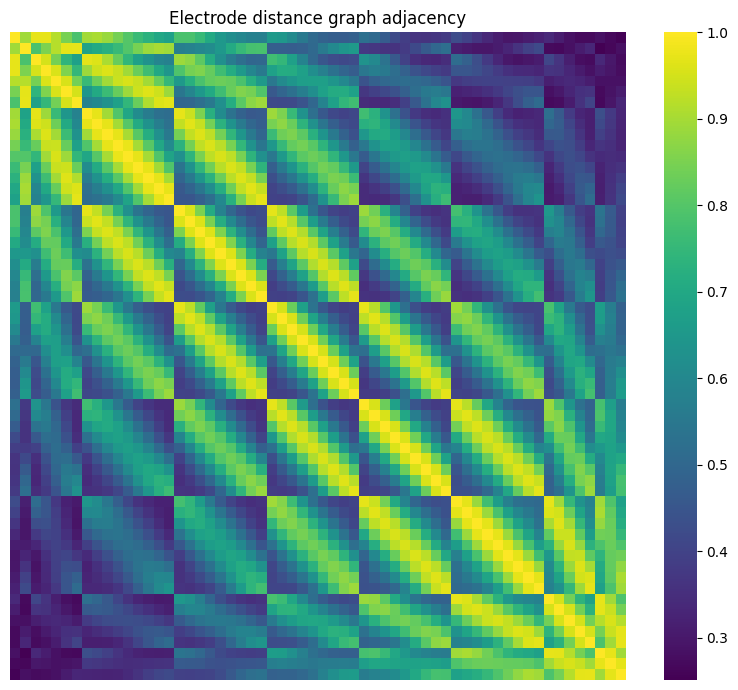

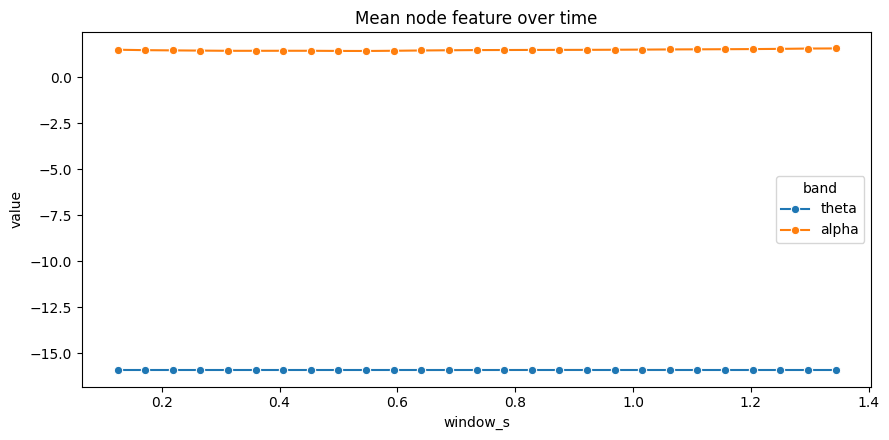

In [ ]:
spec = RawEpochSpec(
    picks=None,
    bandpass=(4.0, 13.0),
    resample_sfreq=128.0,
)
dataset = load_raw_epoch_dataset(paths, task, spec)
X_raw = np.asarray(dataset.X, dtype=np.float32)
y = np.asarray(dataset.y, dtype=np.int64)
subjects = np.asarray(dataset.subjects, dtype=object)
SUBJECT_ID = dataset.subject_ids[0]  # Change this value to train/evaluate another subject.
ch_names = list(dataset.channel_names)
sfreq = 1.0 / float(np.median(np.diff(dataset.times)))

bands = {"theta": (5.0, 7.0), "alpha": (8.0, 12.0)}
X_graph, window_centers, band_names = temporal_band_features(
    X_raw,
    sfreq,
    bands=bands,
    window_sec=0.500,
    step_sec=0.100,
    mode="of",
)
adjacency = electrode_distance_adjacency(ch_names, threshold=0.35)

print(f"Raw X: {X_raw.shape}  (trials, channels, times)")
print(f"Graph X: {X_graph.shape}  (trials, windows, nodes, bands)")
print(f"Bands: {band_names}")
print(f"Adjacency: {adjacency.shape}, density={(adjacency > 0).mean():.3f}")

plt.figure(figsize=(8, 7))
sns.heatmap(adjacency, xticklabels=False, yticklabels=False, cmap="viridis")
plt.title("Electrode distance graph adjacency")
plt.tight_layout()
plt.savefig(paths.figures_dir / f"adjacency_{TASK_TAG}.png", dpi=160, bbox_inches="tight")
plt.show()

feature_preview = pd.DataFrame(
    {
        "window_s": np.tile(window_centers, len(band_names)),
        "band": np.repeat(band_names, len(window_centers)),
        "value": np.concatenate([X_graph[:, :, :, bi].mean(axis=(0, 2)) for bi in range(len(band_names))]),
    }
)
plt.figure(figsize=(9, 4.5))
sns.lineplot(data=feature_preview, x="window_s", y="value", hue="band", marker="o")
plt.title("Mean node feature over time")
plt.tight_layout()
plt.savefig(paths.figures_dir / f"node_features_over_time_{TASK_TAG}.png", dpi=150, bbox_inches="tight")
plt.show()

## Train ST-GNN ChebConv


In [4]:
n_windows = X_graph.shape[1]
n_nodes = X_graph.shape[2]
n_features = X_graph.shape[3]


def make_model():
    return STGNNChebConv(
        n_nodes=n_nodes,
        in_features=n_features,
        adjacency=adjacency,
        n_classes=2,
        cheb_hidden=32,
        temporal_hidden=64,
        K=3,
        dropout=0.4,
    )


train_cfg = TorchTrainConfig(
    epochs=100,
    batch_size=32,
    lr=1e-3,
    weight_decay=1e-4,
    patience=15,
    n_splits=5,
    val_size=0.2,
    random_seed=RANDOM_SEED,
    device=DEVICE,
    progress=True,
)

metrics, history = cross_validate_torch_model(
    X_graph,
    y,
    make_model,
    train_cfg,
    subjects=subjects,
    subject_id=SUBJECT_ID,
    plot_roc_pr=True,
    figures_dir=paths.figures_dir,
    task_tag=TASK_TAG,
)
metrics_path = paths.tables_dir / f"cv_metrics_{TASK_TAG}.csv"
history_path = paths.tables_dir / f"training_history_{TASK_TAG}.csv"
metrics.to_csv(metrics_path, index=False)
history.to_csv(history_path, index=False)
print(f"Saved metrics: {metrics_path}")
print(f"Saved history: {history_path}")
metrics

Fold 1: acc=0.548, bal_acc=0.548, auc=0.583
Fold 3: acc=0.517, bal_acc=0.518, auc=0.543
Fold 5: acc=0.544, bal_acc=0.544, auc=0.553
Saved metrics: /content/drive/MyDrive/TFG_Nils_2026/04_Anàlisi/c_vs_i_stgnn/tables/cv_metrics_c_vs_ip_stgnn.csv
Saved history: /content/drive/MyDrive/TFG_Nils_2026/04_Anàlisi/c_vs_i_stgnn/tables/training_history_c_vs_ip_stgnn.csv


,test_loss,test_acc,test_balanced_acc,test_auc,best_val_acc,epochs_ran,fold
0,0.682822,0.548043,0.548043,0.582905,0.588432,36,1
1,0.685803,0.545859,0.545776,0.557821,0.568409,41,2
2,0.692497,0.517364,0.517530,0.542521,0.566185,24,3
3,0.684355,0.549421,0.549646,0.572532,0.563960,32,4
4,0.690063,0.544078,0.544086,0.553045,0.576196,39,5


## Visualize Training


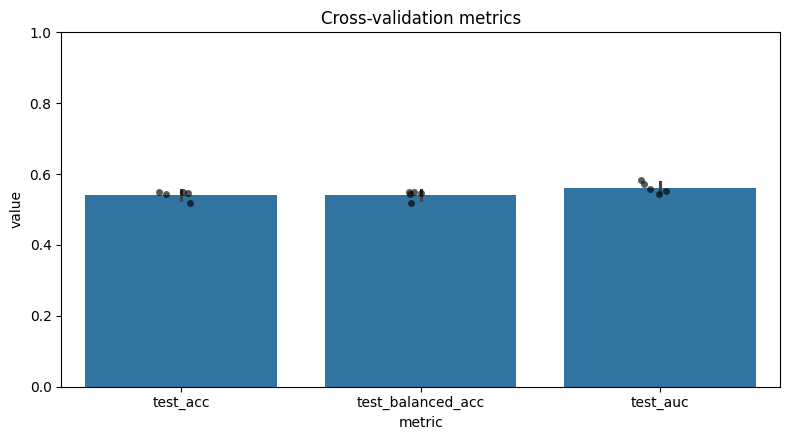

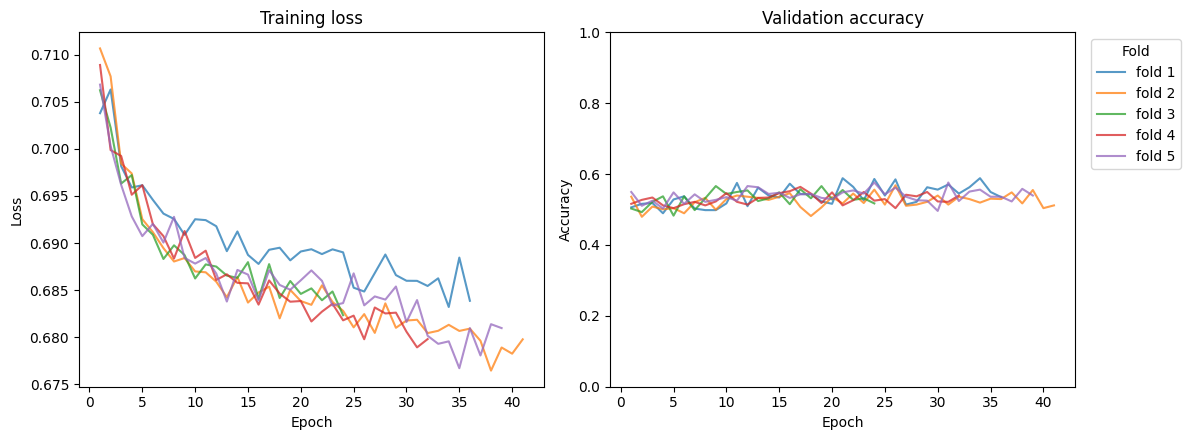

Saved summary: /content/drive/MyDrive/TFG_Nils_2026/04_Anàlisi/c_vs_i_stgnn/tables/summary_c_vs_ip_stgnn.csv


,metric,mean,std
0,test_loss,0.687108,0.004045
1,test_acc,0.540953,0.013344
2,test_balanced_acc,0.541016,0.013300
3,test_auc,0.561765,0.016006
4,best_val_acc,0.572636,0.009962
5,epochs_ran,34.400000,6.730527


In [5]:
plot_fold_metrics(metrics, output_file=paths.figures_dir / f"fold_metrics_{TASK_TAG}.png")
plot_torch_history(history, output_file=paths.figures_dir / f"training_history_{TASK_TAG}.png")

summary = metrics.drop(columns=["fold"]).agg(["mean", "std"]).T.reset_index().rename(columns={"index": "metric"})
summary_path = paths.tables_dir / f"summary_{TASK_TAG}.csv"
summary.to_csv(summary_path, index=False)
print(f"Saved summary: {summary_path}")
summary

In [ ]:
# We run Epochs Grid for ST-GNN to draw the learning curve using the binomial analytical chance level
epochs_grid = get_epochs_grid("c_vs_ip")


# Make model constructor using current adjacency matrix
def make_model_stgnn():
    return STGNNChebConv(
        n_nodes=60,
        in_features=2,
        adjacency=adjacency,
        n_classes=2,
        cheb_hidden=32,
        temporal_hidden=64,
        K=3,
        dropout=0.4,
    )


print(f"Running ST-GNN Epochs Grid for {epochs_grid} epochs on subject {SUBJECT_ID}...")
df_grid = run_torch_epochs_grid(
    X_graph, y, make_model_stgnn, train_cfg, epochs_grid, n_repeats=5, subjects=subjects, subject_id=SUBJECT_ID
)
df_grid.to_csv(paths.tables_dir / f"epochs_grid_metrics_{TASK_TAG}.csv", index=False)

# Plot learning curve
plt.figure(figsize=(7, 4.5))
plt.plot(df_grid["n_epochs_total"], df_grid["acc_real_mean"], "s-", label="ST-GNN Real Accuracy", color="green")
plt.fill_between(
    df_grid["n_epochs_total"],
    df_grid["acc_real_mean"] - df_grid["acc_real_std"],
    df_grid["acc_real_mean"] + df_grid["acc_real_std"],
    alpha=0.15,
    color="green",
)
plt.plot(df_grid["n_epochs_total"], df_grid["acc_chance_mean"], "k--", label="Chance Baseline (50%)")
plt.plot(df_grid["n_epochs_total"], df_grid["acc_chance_q95"], "r--", label="Analytical Chance Level (Q95)")
plt.title(f"ST-GNN ChebConv Epochs Grid - Subject {SUBJECT_ID}")
plt.xlabel("Total epochs loaded")
plt.ylabel("Classification Accuracy")
plt.legend()
plt.grid(True, linestyle=":")
plt.tight_layout()
epochs_plot_path = paths.figures_dir / f"epochs_grid_{TASK_TAG}.png"
plt.savefig(epochs_plot_path, dpi=180, bbox_inches="tight")
plt.show()
print(f"ST-GNN Epochs grid plot saved to: {epochs_plot_path}")